Importing the Dependencies

In [1]:
import numpy as np
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report

Data Collection and Analysis

Diabetes Dataset

In [2]:
#loading diabetes dataset
diabetes_dataset = pd.read_csv('diabetes.csv')

In [3]:
#loading the first 5 rows
diabetes_dataset.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [4]:
diabetes_dataset.drop(columns=['gender','smoking_history'],axis=1,inplace=True)

In [5]:
#numbers of rows and columns
diabetes_dataset.shape

(100000, 7)

In [6]:
#checking for missing values
diabetes_dataset.isna().sum()

age                    0
hypertension           0
heart_disease          0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

In [7]:
#getting the statistical measures of the data
diabetes_dataset.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
count,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,41.885856,0.07485,0.039420,27.320767,5.527507,138.058060,0.085000
std,22.516840,0.26315,0.194593,6.636783,1.070672,40.708136,0.278883
min,0.080000,0.00000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,24.000000,0.00000,0.000000,23.630000,4.800000,100.000000,0.000000
50%,43.000000,0.00000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,60.000000,0.00000,0.000000,29.580000,6.200000,159.000000,0.000000
max,80.000000,1.00000,1.000000,95.690000,9.000000,300.000000,1.000000


In [8]:
#number of diabetic and non-diabetic 
diabetes_dataset['diabetes'].value_counts()

diabetes
0    91500
1     8500
Name: count, dtype: int64

HIGHLY IMBALANCED DATASET 0------> NON-DIABETIC 1------> DIABETIC 

In [9]:
Non_diabetic = diabetes_dataset[diabetes_dataset.diabetes == 0]
Diabetic = diabetes_dataset[diabetes_dataset.diabetes == 1]

In [10]:
print(Non_diabetic.shape,Diabetic.shape)

(91500, 7) (8500, 7)


under_sampling build a sample dataset containing similar distribution of Non-Diabetic & Diabetic Patients

In [11]:
Non_diabetic_sample = Non_diabetic.sample(n=8500, random_state=2)

In [12]:
Non_diabetic_sample.shape

(8500, 7)

Concatenate The Two Dataframes

In [13]:
New_Diabetes_dataset = pd.concat([Non_diabetic_sample, Diabetic], axis = 0)

In [14]:
New_Diabetes_dataset.head()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
90088,26.0,0,0,27.68,6.0,140,0
73279,80.0,0,0,28.29,6.5,100,0
99498,25.0,0,0,27.06,6.6,200,0
69122,50.0,0,0,23.13,5.7,85,0
95877,68.0,1,0,32.50,4.0,160,0


In [15]:
New_Diabetes_dataset = New_Diabetes_dataset.reset_index(drop=True)

In [16]:
New_Diabetes_dataset

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
0,26.0,0,0,27.68,6.0,140,0
1,80.0,0,0,28.29,6.5,100,0
2,25.0,0,0,27.06,6.6,200,0
3,50.0,0,0,23.13,5.7,85,0
4,68.0,1,0,32.50,4.0,160,0
...,...,...,...,...,...,...,...
16995,65.0,1,1,33.55,8.2,140,1
16996,55.0,0,1,30.42,6.2,300,1
16997,61.0,0,0,34.45,6.5,280,1
16998,58.0,1,0,38.31,7.0,200,1


In [17]:
#separating features and labels
X = New_Diabetes_dataset.drop(columns='diabetes', axis=1)
Y = New_Diabetes_dataset['diabetes']

In [18]:
pd.DataFrame(X)

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level
0,26.0,0,0,27.68,6.0,140
1,80.0,0,0,28.29,6.5,100
2,25.0,0,0,27.06,6.6,200
3,50.0,0,0,23.13,5.7,85
4,68.0,1,0,32.50,4.0,160
...,...,...,...,...,...,...
16995,65.0,1,1,33.55,8.2,140
16996,55.0,0,1,30.42,6.2,300
16997,61.0,0,0,34.45,6.5,280
16998,58.0,1,0,38.31,7.0,200


In [19]:
pd.DataFrame(Y)

,diabetes
0,0
1,0
2,0
3,0
4,0
...,...
16995,1
16996,1
16997,1
16998,1


Train Test Split

We split *before* standardizing so the test data does not influence the scaler (avoids data leakage).

In [20]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, stratify=Y, random_state=2)

In [21]:
print(X.shape, X_train.shape, X_test.shape)

(17000, 6) (13600, 6) (3400, 6)


Data Standardization

The scaler is fitted on the training data only, then applied to both sets.

In [22]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train.values)
X_test = scaler.transform(X_test.values)

Training the Model

In [23]:
Log_reg = LogisticRegression(max_iter=10000)

In [24]:
#training the Logistic Regression model
Log_reg.fit(X_train, Y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,10000
,multi_class,'deprecated'


Model Evaluation 

In [25]:
#accuracy score on the training data
X_train_prediction = Log_reg.predict(X_train)
training_data_accuracy = accuracy_score(X_train_prediction,Y_train)

In [26]:
print('Accuracy of the training data : ', round(training_data_accuracy*100, 2),'%')

Accuracy of the training data :  88.69 %


In [27]:
#accuracy score on the test data
X_test_prediction = Log_reg.predict(X_test)
testing_data_accuracy = accuracy_score(X_test_prediction,Y_test)

In [28]:
print('Accuracy of the testing data : ', round(testing_data_accuracy*100, 2),'%')
print("Classification Report:\n", classification_report(Y_test, X_test_prediction))

Accuracy of the testing data :  88.38 %
Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.89      0.88      1700
           1       0.89      0.88      0.88      1700

    accuracy                           0.88      3400
   macro avg       0.88      0.88      0.88      3400
weighted avg       0.88      0.88      0.88      3400



True Negative: 1516
False Positive: 184
False Negative: 211
True Positive: 1489


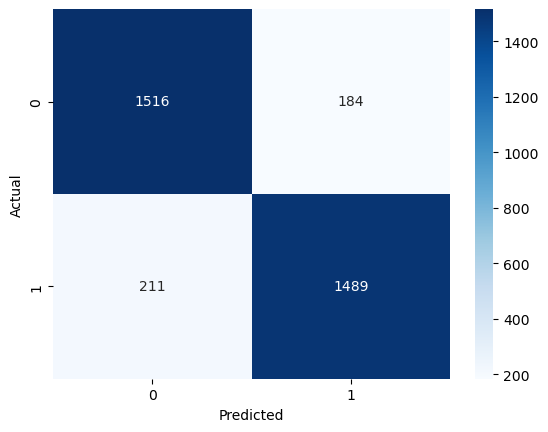

In [29]:
Confusion_matrix = confusion_matrix(Y_test, X_test_prediction)  # (y_true, y_pred)
tn, fp, fn, tp = Confusion_matrix.ravel()
print("True Negative:", tn)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Positive:", tp)
sns.heatmap(Confusion_matrix, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

Making a Predictive System

In [30]:
# order: age, hypertension, heart_disease, bmi, HbA1c_level, blood_glucose_level
input_data = (50.0,0,0,37.16,9.0,159)

#change input_data to numpy array
input_data_as_numpy_array = np.asarray(input_data)

#reshape the array as we are predicting for one instance
input_data_reshaped = input_data_as_numpy_array.reshape(1,-1)

#standardize input_data
std_data = scaler.transform(input_data_reshaped)
print(std_data)

prediction = Log_reg.predict(std_data)
print(prediction)

if (prediction[0]==0):
    print('The person is not diabetic')
else:
    print('The Person is diabetic')

[[-0.02095901 -0.42250388 -0.30464464  1.06425936  2.21529997 -0.07643155]]
[1]
The Person is diabetic
